# GMM — Monitoramento ambiental | versão limpa (2,5 segundos)

**Objetivo:** classificação binária de sons ambientais usando **20 GMMs especialistas** treinados com classes normais (0–19), mais uma **regressão logística** que combina os scores para identificar anomalias (40–49).

**Pipeline preservado da versão experimental:** gravações ESC-50 de 5 s → duas metades de 2,5 s → extração dos atributos → 20 GMMs → 26 atributos de fusão → regressão logística → **média dos scores dos dois segmentos** → uma predição por gravação.

- **Treino dos GMMs e seleção de atributos:** folds 1–3; apenas sons normais.
- **Treino da fusão e escolha do limiar:** fold 4 (normais + anomalias), com predições de validação cruzada agrupada para escolher o limiar.
- **Avaliação:** fold 5 (160 áudios normais e 80 anômalos).

**Por que ainda há extração de 5 segundos?** Na implementação escolhida, os 12 atributos foram selecionados a partir dos **áudios de 5 s dos folds 1–3** e aplicados aos segmentos de 2,5 s. Manter essa seleção reproduz a configuração já avaliada; **nenhum GMM de 5 s é treinado** nesta versão.

*Os experimentos de duração híbrida, agregações alternativas e calibração exploratória foram removidos. Como o fold 5 já foi inspecionado durante o desenvolvimento, não tratá-lo como teste totalmente cego em futuras otimizações.*

### A. Ambiente e metadados

In [1]:
# Execute em Colab (o ESC-50 é clonado somente se a pasta não existir).
!test -d ESC-50 || git clone https://github.com/karolpiczak/ESC-50.git


Cloning into 'ESC-50'...
remote: Enumerating objects: 4199, done.
remote: Counting objects: 100% (69/69), done.
remote: Compressing objects: 100% (35/35), done.
remote: Total 4199 (delta 62), reused 34 (delta 34), pack-reused 4130 (from 1)
Receiving objects: 100% (4199/4199), 878.77 MiB | 4.57 MiB/s, done.
Resolving deltas: 100% (292/292), done.
Updating files: 100% (2011/2011), done.


In [2]:
import os
import warnings
import numpy as np
import pandas as pd
import librosa
from tqdm.auto import tqdm
from scipy.special import xlogy, logsumexp
from sklearn.feature_selection import f_classif
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import GroupKFold, StratifiedGroupKFold
from sklearn.pipeline import make_pipeline
from sklearn.mixture import GaussianMixture
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    roc_auc_score, roc_curve, average_precision_score,
    accuracy_score, balanced_accuracy_score, classification_report,
    confusion_matrix, recall_score, f1_score
)

SR = 16000
PASTA_AUDIO = 'ESC-50/audio/'
caminho_csv = 'ESC-50/meta/esc50.csv'
SEMENTE = 42
FOLDS_TREINO = (1, 2, 3)
FOLD_DESENV = 4
FOLD_TESTE = 5

# Configuração congelada do sistema de 2,5 segundos.
N_COMPONENTES = (1, 2, 3, 4, 5, 6, 8, 10)
TIPOS_COVARIANCIA = ('diag',)
REG_COVAR = 1e-3
N_INIT = 2
N_ATRIBUTOS = 12
REFORCAR_EXTRACAO = False
CACHE = 'v11_gmm_features_5s_2p5s.pkl'

meta_esc = pd.read_csv(caminho_csv)
meta_esc = meta_esc.loc[
    meta_esc['target'].between(0, 19) | meta_esc['target'].between(40, 49),
    ['filename', 'target', 'category', 'fold', 'src_file']
].copy().reset_index(drop=True)
assert len(meta_esc) == 1200 and meta_esc['filename'].is_unique
assert set(meta_esc['fold']) == {1, 2, 3, 4, 5}
print('Gravações selecionadas:', len(meta_esc))


Gravações selecionadas: 1200


### B. Extração de características acústicas

In [3]:
def estatisticas(vetor, prefixo):
    a = np.asarray(vetor, dtype=float).ravel()
    return {
        f'{prefixo}_mean': float(np.mean(a)),
        f'{prefixo}_std': float(np.std(a)),
        f'{prefixo}_median': float(np.median(a)),
        f'{prefixo}_min': float(np.min(a)),
        f'{prefixo}_max': float(np.max(a)),
    }


def extrair_experimento_C(caminho=None, n_mfcc=5, sr=SR, y=None):
    # As 102 características da V10 em áudio completo ou segmento em memória.
    if y is None:
        if caminho is None:
            raise ValueError('Informe caminho ou y')
        y, sr = librosa.load(caminho, sr=sr, mono=True)
    else:
        y = np.asarray(y, dtype=np.float32)
    if y.ndim != 1 or len(y) < sr:
        raise ValueError('Trecho precisa ser mono e ter pelo menos 1 s')

    f = {}
    mfcc = librosa.feature.mfcc(y=y, sr=sr, n_mfcc=n_mfcc)
    for i in range(n_mfcc):
        f.update(estatisticas(mfcc[i], f'mfcc_{i+1}'))
    d1 = librosa.feature.delta(mfcc)
    d2 = librosa.feature.delta(mfcc, order=2)
    for i in range(n_mfcc):
        f.update(estatisticas(d1[i], f'delta_{i+1}'))
        f.update(estatisticas(d2[i], f'delta_delta_{i+1}'))

    f.update(estatisticas(librosa.feature.zero_crossing_rate(y)[0], 'zcr'))
    f.update(estatisticas(librosa.feature.spectral_centroid(y=y, sr=sr)[0], 'centroid'))
    espectro = np.abs(librosa.stft(y))
    frequencias = librosa.fft_frequencies(sr=sr)
    f.update(estatisticas(frequencias[np.argmax(espectro, axis=0)], 'freq_dominante'))

    onsets = librosa.onset.onset_detect(y=y, sr=sr)
    f['pulsos_por_segundo'] = float(len(onsets) / (len(y) / sr))
    rms = librosa.feature.rms(y=y)[0]
    f['percentual_silencio'] = float(np.mean(rms < np.max(rms) * 0.05))

    # Evita NaN em frames sem energia; em frames válidos coincide com entropia original.
    potencia = espectro ** 2
    total = np.sum(potencia, axis=0, keepdims=True)
    prob = np.divide(potencia, total, out=np.zeros_like(potencia), where=total > 0)
    entropia = -np.sum(xlogy(prob, prob), axis=0)
    f.update(estatisticas(entropia, 'entropia_espectral'))
    f.update(estatisticas(librosa.onset.onset_strength(y=y, sr=sr), 'fluxo_espectral'))
    return f


### C. Preparação das gravações e segmentos

In [4]:
if os.path.isfile(CACHE) and not REFORCAR_EXTRACAO:
    cache = pd.read_pickle(CACHE)
    df_5s, df_2p5s = cache['df_5s'], cache['df_2p5s']
    print('Carregado do cache:', CACHE)
else:
    reg_5s, reg_seg = [], []
    for a in tqdm(meta_esc.itertuples(index=False), total=len(meta_esc), desc='Extraindo características acústicas'):
        caminho = os.path.join(PASTA_AUDIO, a.filename)
        y, sr = librosa.load(caminho, sr=SR, mono=True)
        metadata = dict(filename=a.filename, target=int(a.target), category=a.category,
                        fold=int(a.fold), src_file=a.src_file)
        f5 = extrair_experimento_C(y=y, sr=sr, n_mfcc=5)
        reg_5s.append({**f5, **metadata, 'segmento': 0})
        metade = len(y) // 2
        for j, ys in enumerate((y[:metade], y[metade:]), start=1):
            fs = extrair_experimento_C(y=ys, sr=sr, n_mfcc=5)
            reg_seg.append({**fs, **metadata, 'segmento': j,
                            'energia_rms': float(np.sqrt(np.mean(ys.astype(np.float64) ** 2)))})
    df_5s, df_2p5s = pd.DataFrame(reg_5s), pd.DataFrame(reg_seg)
    pd.to_pickle({'df_5s': df_5s, 'df_2p5s': df_2p5s}, CACHE)
    print('Cache salvo:', CACHE)

META = {'filename', 'target', 'category', 'fold', 'src_file', 'segmento', 'energia_rms'}
COLUNAS_ACUSTICAS = [c for c in df_5s.columns if c not in META]
assert len(df_5s) == 1200 and len(df_2p5s) == 2400
assert df_5s['filename'].is_unique
assert df_2p5s.groupby('filename').size().eq(2).all()
assert df_2p5s.groupby('filename')['target'].nunique().eq(1).all()
assert df_2p5s.groupby('filename')['fold'].nunique().eq(1).all()
assert set(COLUNAS_ACUSTICAS) == set(df_2p5s.columns) - META
for nome, tabela in [('5 s', df_5s), ('2,5 s', df_2p5s)]:
    X = tabela[COLUNAS_ACUSTICAS].to_numpy(dtype=float)
    r, c = np.where(~np.isfinite(X))
    if len(r):
        print('Problemas no conjunto', nome)
        display(pd.DataFrame({'arquivo': tabela.iloc[r]['filename'].values,
                              'atributo': np.asarray(COLUNAS_ACUSTICAS)[c]}).head(30))
        raise ValueError('Características inválidas. Reextrair com REFORCAR_EXTRACAO=True após corrigir a função.')
    print(nome, tabela.shape, 'atributos:', X.shape[1])

# Escopo de cada fold (a avaliação é sempre por gravação original).
def particao(tabela, nome):
    if nome == 'treino': return tabela[tabela['fold'].isin(FOLDS_TREINO)].copy().reset_index(drop=True)
    if nome == 'desenv': return tabela[tabela['fold'] == FOLD_DESENV].copy().reset_index(drop=True)
    if nome == 'teste': return tabela[tabela['fold'] == FOLD_TESTE].copy().reset_index(drop=True)
    raise ValueError(nome)

print('Treino 2,5 s:', len(particao(df_2p5s, 'treino')))
print('Gravações de teste:', particao(df_2p5s, 'teste')['filename'].nunique())


Extraindo características acústicas:   0%|          | 0/1200 [00:00<?, ?it/s]

Cache salvo: v11_gmm_features_5s_2p5s.pkl
5 s (1200, 108) atributos: 102
2,5 s (2400, 109) atributos: 102
Treino 2,5 s: 1440
Gravações de teste: 240


### D. Seleção dos 12 atributos no treino

In [5]:
def selecionar_atributos_treino_5s(tabela, colunas, n=12, correlacao_max=0.80):
    normais = particao(tabela, 'treino')
    normais = normais[normais['target'].between(0, 19)]
    X = normais[colunas].to_numpy(dtype=float)
    y = normais['target'].to_numpy()
    with warnings.catch_warnings():
        warnings.simplefilter('ignore')
        f, _ = f_classif(X, y)
    ranking = (pd.DataFrame({'atributo': colunas, 'F_score': f})
               .replace([np.inf, -np.inf], np.nan)
               .dropna(subset=['F_score'])
               .sort_values('F_score', ascending=False))
    corr = normais[ranking['atributo']].corr().abs()
    usados = []
    for col in ranking['atributo']:
        if all(pd.notna(corr.loc[col, x]) and corr.loc[col, x] < correlacao_max for x in usados):
            usados.append(col)
        if len(usados) == n:
            break
    if len(usados) < n:
        raise ValueError(f'Não foi possível escolher {n} atributos sem redundância (selecionados: {len(usados)})')
    return usados, ranking

atributos_treino, ranking_treino = selecionar_atributos_treino_5s(df_5s, COLUNAS_ACUSTICAS, N_ATRIBUTOS)
atributos_finais = atributos_treino
assert len(atributos_finais) == 12
assert set(atributos_finais).issubset(COLUNAS_ACUSTICAS)
print('Atributos usados no GMM 2,5 s:')
for i, c in enumerate(atributos_finais, 1): print(f'{i:2d}. {c}')


Atributos usados no GMM 2,5 s:
 1. delta_delta_1_min
 2. delta_delta_3_max
 3. mfcc_3_min
 4. mfcc_1_mean
 5. mfcc_2_max
 6. mfcc_3_std
 7. delta_delta_2_max
 8. delta_4_std
 9. mfcc_1_max
10. centroid_mean
11. centroid_max
12. mfcc_2_min


### E. Treinamento dos 20 GMMs de 2,5 s

In [6]:
# Mais rigor que escolher os hiperparâmetros com as anomalias do fold 4 e depois
# voltar a usar esse mesmo fold para estimar a qualidade da fusão.
# Cada metade do mesmo arquivo permanece na mesma dobra de CV (GroupKFold).

def grupos_de_origem(tabela):
    origem = tabela['src_file'].astype('string').fillna('')
    origem = origem.where(origem.str.strip() != '', tabela['filename'].astype(str))
    return origem.astype(str).to_numpy()


def treinar_20_gmms(tabela, atributos):
    treino = particao(tabela, 'treino')
    treino = treino[treino['target'].between(0, 19)].copy()
    modelos, refs, configs = {}, {}, []

    for classe in tqdm(range(20), desc='Treinando GMMs'):
        part = treino[treino['target'] == classe].copy()
        X = part[atributos].to_numpy(dtype=float)
        grupos = grupos_de_origem(part)
        if len(np.unique(grupos)) < 3:
            raise ValueError(f'Classe {classe}: menos de 3 gravações de origem independentes')
        splits = list(GroupKFold(n_splits=3).split(X, groups=grupos))

        melhor = None
        for cov in TIPOS_COVARIANCIA:
            for k in N_COMPONENTES:
                if any(k > len(tr) for tr, _ in splits):
                    continue
                oof = np.full(len(X), np.nan, dtype=float)
                valido = True
                for tr, ho in splits:
                    scaler_cv = StandardScaler().fit(X[tr])
                    gmm_cv = GaussianMixture(
                        n_components=k, covariance_type=cov,
                        reg_covar=REG_COVAR, n_init=N_INIT,
                        random_state=SEMENTE, max_iter=300
                    )
                    try:
                        gmm_cv.fit(scaler_cv.transform(X[tr]))
                        oof[ho] = gmm_cv.score_samples(scaler_cv.transform(X[ho]))
                    except (ValueError, np.linalg.LinAlgError):
                        valido = False
                        break
                if not valido or not np.isfinite(oof).all():
                    continue
                media = float(np.mean(oof))
                # Em caso de empate, escolher menos componentes.
                if melhor is None or media > melhor['media'] + 1e-9 or (
                    abs(media - melhor['media']) <= 1e-9 and k < melhor['k']
                ):
                    melhor = dict(k=k, cov=cov, media=media, oof=oof.copy())

        if melhor is None:
            raise RuntimeError(f'Não foi possível ajustar GMM para a classe {classe}')
        scaler = StandardScaler().fit(X)
        modelo = GaussianMixture(
            n_components=melhor['k'], covariance_type=melhor['cov'],
            reg_covar=REG_COVAR, n_init=N_INIT,
            random_state=SEMENTE, max_iter=300
        ).fit(scaler.transform(X))
        modelos[classe] = dict(modelo=modelo, scaler=scaler,
                              n_components=melhor['k'], covariance_type=melhor['cov'])
        # Os scores OOF dos mesmos segmentos são estimativas correlacionadas —
        # úteis para calibrar, NÃO são um teste independente.
        refs[classe] = melhor['oof']
        configs.append(dict(classe=classe, n_treino=len(X), n_arquivos=part['filename'].nunique(),
                            n_components=melhor['k'], covariancia=melhor['cov'],
                            loglik_cv=melhor['media']))

    return dict(modelos=modelos, refs=refs,
                atributos=list(atributos), tabela=pd.DataFrame(configs))


experimento_gmm_2p5s = treinar_20_gmms(df_2p5s, atributos_finais)
print('20 especialistas treinados com segmentos de 2,5 s:')
display(experimento_gmm_2p5s['tabela'])


Treinando GMMs:   0%|          | 0/20 [00:00<?, ?it/s]

20 especialistas treinados com segmentos de 2,5 s:


,classe,n_treino,n_arquivos,n_components,covariancia,loglik_cv
0,0,48,24,1,diag,-18.835355
1,1,48,24,2,diag,-11.758642
2,2,48,24,1,diag,-26.937564
3,3,48,24,3,diag,-8.187935
4,4,48,24,1,diag,-19.636743
5,5,48,24,3,diag,-14.205777
6,6,48,24,2,diag,-11.999173
7,7,48,24,1,diag,-19.980017
8,8,48,24,1,diag,-27.966387
9,9,48,24,1,diag,-21.928649


### F. Pontuações e 26 características para fusão

In [7]:
# Mesmas ideias de agregação da V10. Cada GMM possui seu próprio scaler.
def scores_20_gmms(tabela, exp):
    X = tabela[exp['atributos']].to_numpy(dtype=float)
    return np.column_stack([
        exp['modelos'][c]['modelo'].score_samples(
            exp['modelos'][c]['scaler'].transform(X)
        ) for c in range(20)
    ])


def preparar_fusao(exp):
    medianas = np.array([np.median(exp['refs'][c]) for c in range(20)])
    mad = np.array([1.4826 * np.median(np.abs(exp['refs'][c] - medianas[c]))
                    for c in range(20)])
    escalas = np.maximum(mad, 1e-3)
    return dict(med=medianas, esc=escalas)


def caracteristicas_fusao(S, cfg):
    Z = (S - cfg['med']) / cfg['esc']
    T = np.arcsinh(Z)
    Ts = np.sort(T, axis=1)[:, ::-1]
    return np.column_stack([
        T, Ts[:, 0], Ts[:, 1], Ts[:, :3].mean(axis=1),
        logsumexp(T, axis=1), T.std(axis=1), (Z > -2).sum(axis=1)
    ])



def dataset_meta(tabela, exp, part):
    subset = particao(tabela, part)
    S = scores_20_gmms(subset, exp)
    cfg = preparar_fusao(exp)
    F = caracteristicas_fusao(S, cfg)
    y = (subset['target'].to_numpy() >= 40).astype(int)
    grupos = grupos_de_origem(subset)
    return dict(tabela=subset, S=S, F=F, y=y, grupos=grupos, cfg=cfg)

meta_dev_2p5s = dataset_meta(df_2p5s, experimento_gmm_2p5s, 'desenv')
assert meta_dev_2p5s['F'].shape == (480, 26)
assert np.isfinite(meta_dev_2p5s['F']).all()
print('Características da fusão:', meta_dev_2p5s['F'].shape)
print('Gravações distintas:', meta_dev_2p5s['tabela']['filename'].nunique())


Características da fusão: (480, 26)
Gravações distintas: 240


### G. Regressão logística e limiar de decisão no fold 4

In [8]:
# Configuração selecionada nos experimentos anteriores.
METODO_FUSAO = 'stacking: regressão logística'
AGREGACAO = 'mean'


def treinar_modelo_fusao(F, y):
    modelo = make_pipeline(
        StandardScaler(),
        LogisticRegression(
            C=0.1,
            class_weight='balanced',
            max_iter=3000,
            random_state=SEMENTE
        )
    )
    return modelo.fit(F, y)


def pontuar_modelo_fusao(modelo, F):
    return modelo.predict_proba(F)[:, 1]


def agregar_por_audio(tabela, scores):
    x = tabela[['filename', 'target', 'category']].copy()
    x['score'] = np.asarray(scores, dtype=float)
    x['y_real'] = (x['target'] >= 40).astype(int)
    res = (
        x.groupby('filename', sort=True)
        .agg(score=('score', 'mean'), y_real=('y_real', 'first'),
             target=('target', 'first'), category=('category', 'first'))
        .reset_index()
    )
    assert len(res) == tabela['filename'].nunique()
    return res


def limiar_balanced_accuracy(y, scores):
    fpr, tpr, limiares = roc_curve(y, scores)
    validos = np.isfinite(limiares)
    if not validos.any():
        raise ValueError('Nenhum limiar válido')
    idx = np.argmax(np.where(validos, tpr - fpr, -np.inf))
    return float(limiares[idx])


# Escolher o limiar somente com previsões out-of-fold do fold 4.
F_dev = meta_dev_2p5s['F']
y_dev = meta_dev_2p5s['y']
grupos_dev = meta_dev_2p5s['grupos']
cv = StratifiedGroupKFold(n_splits=4, shuffle=True, random_state=SEMENTE)
scores_oof = np.full(len(y_dev), np.nan)

for indices_treino, indices_validacao in cv.split(F_dev, y_dev, groups=grupos_dev):
    assert set(np.unique(y_dev[indices_treino])) == {0, 1}
    assert set(np.unique(y_dev[indices_validacao])) == {0, 1}
    modelo_cv = treinar_modelo_fusao(F_dev[indices_treino], y_dev[indices_treino])
    scores_oof[indices_validacao] = pontuar_modelo_fusao(
        modelo_cv, F_dev[indices_validacao]
    )

assert np.isfinite(scores_oof).all()
validacao_audio = agregar_por_audio(meta_dev_2p5s['tabela'], scores_oof)
y_audio_dev = validacao_audio['y_real'].to_numpy()
s_audio_dev = validacao_audio['score'].to_numpy()
limiar_gmm_2p5s = limiar_balanced_accuracy(y_audio_dev, s_audio_dev)
pred_dev = (s_audio_dev >= limiar_gmm_2p5s).astype(int)

# Treino final da fusão: TODO o fold 4, sem envolver o fold 5.
modelo_fusao_gmm_2p5s = treinar_modelo_fusao(F_dev, y_dev)

print('Método:', METODO_FUSAO)
print('Agregação:', AGREGACAO)
print('Limiar definido no desenvolvimento:', round(limiar_gmm_2p5s, 5))
print('ROC-AUC de validação (por gravação):',
      round(roc_auc_score(y_audio_dev, s_audio_dev), 4))
print('Balanced accuracy de validação:',
      round(balanced_accuracy_score(y_audio_dev, pred_dev), 4))
print('Recall anomalias na validação:',
      round(recall_score(y_audio_dev, pred_dev, pos_label=1), 4))


Método: stacking: regressão logística
Agregação: mean
Limiar definido no desenvolvimento: 0.60182
ROC-AUC de validação (por gravação): 0.7987
Balanced accuracy de validação: 0.7281
Recall anomalias na validação: 0.6


### H. Avaliação no fold 5

In [9]:
# Avaliação por gravação original no fold 5 (160 normais + 80 anomalias).
meta_teste_2p5s = dataset_meta(df_2p5s, experimento_gmm_2p5s, 'teste')
scores_segmentos_teste = pontuar_modelo_fusao(
    modelo_fusao_gmm_2p5s, meta_teste_2p5s['F']
)
predicoes_gmm_2p5s = agregar_por_audio(
    meta_teste_2p5s['tabela'], scores_segmentos_teste
)
predicoes_gmm_2p5s['pred_binaria'] = (
    predicoes_gmm_2p5s['score'] >= limiar_gmm_2p5s
).astype(int)

y = predicoes_gmm_2p5s['y_real'].to_numpy()
scores = predicoes_gmm_2p5s['score'].to_numpy()
pred = predicoes_gmm_2p5s['pred_binaria'].to_numpy()
matriz_confusao = confusion_matrix(y, pred, labels=[0, 1])

metricas_gmm_2p5s = {
    'modelo': 'GMM 2,5 s',
    'metodo': METODO_FUSAO,
    'agregacao': AGREGACAO,
    'n_audios': len(y),
    'roc_auc': roc_auc_score(y, scores),
    'avg_precision': average_precision_score(y, scores),
    'acuracia': accuracy_score(y, pred),
    'balanced_accuracy': balanced_accuracy_score(y, pred),
    'f1_anomalia': f1_score(y, pred),
    'recall_normal': recall_score(y, pred, pos_label=0),
    'recall_anomalia': recall_score(y, pred, pos_label=1),
    'falsos_positivos': int(matriz_confusao[0, 1]),
    'falsos_negativos': int(matriz_confusao[1, 0]),
}

assert len(predicoes_gmm_2p5s) == 240
print('RESULTADOS GMM 2,5 s — FOLD 5')
display(pd.DataFrame([metricas_gmm_2p5s]).round(4))
print('\nMatriz de confusão por gravação (real nas linhas, previsto nas colunas):')
print(matriz_confusao)
print(classification_report(y, pred, target_names=['Normal', 'Anomalia'],
                            digits=3, zero_division=0))


RESULTADOS GMM 2,5 s — FOLD 5


,modelo,metodo,agregacao,n_audios,roc_auc,avg_precision,acuracia,balanced_accuracy,f1_anomalia,recall_normal,recall_anomalia,falsos_positivos,falsos_negativos
0,"GMM 2,5 s",stacking: regressão logística,mean,240,0.8298,0.6964,0.7292,0.6719,0.5517,0.8438,0.5,25,40



Matriz de confusão por gravação (real nas linhas, previsto nas colunas):
[[135  25]
 [ 40  40]]
              precision    recall  f1-score   support

      Normal      0.771     0.844     0.806       160
    Anomalia      0.615     0.500     0.552        80

    accuracy                          0.729       240
   macro avg      0.693     0.672     0.679       240
weighted avg      0.719     0.729     0.721       240



### I. Análise de erros por classe e exportação

In [10]:
# Diagnóstico por categoria; avaliar sempre gravações originais, não segmentos.
diagnostico = predicoes_gmm_2p5s.copy()
diagnostico['acertou'] = diagnostico['y_real'] == diagnostico['pred_binaria']
tabela_categorias_gmm = (
    diagnostico.groupby(['target', 'category'])['acertou']
    .agg(taxa_acerto='mean', n_audios='count')
    .reset_index()
    .sort_values(['taxa_acerto', 'target'])
)
display(tabela_categorias_gmm.round(3))

# Exportações finais, sem arquivos de experimentos descartados.
pd.DataFrame([metricas_gmm_2p5s]).to_csv('gmm_2p5s_metricas.csv', index=False)
predicoes_gmm_2p5s.to_csv('gmm_2p5s_predicoes_por_audio.csv', index=False)
tabela_categorias_gmm.to_csv('gmm_2p5s_desempenho_por_categoria.csv', index=False)
experimento_gmm_2p5s['tabela'].to_csv('gmm_2p5s_configuracao_especialistas.csv', index=False)
print('Arquivos CSV exportados.')


,target,category,taxa_acerto,n_audios
11,11,sea_waves,0.000,8
28,48,fireworks,0.000,8
16,16,wind,0.375,8
20,40,helicopter,0.375,8
23,43,car_horn,0.375,8
27,47,airplane,0.375,8
21,41,chainsaw,0.500,8
29,49,hand_saw,0.500,8
9,9,crow,0.625,8
19,19,thunderstorm,0.625,8


Arquivos CSV exportados.


## XAI

IMPORTÂNCIA GLOBAL — REGRESSÃO LOGÍSTICA


,caracteristica,coeficiente,importancia_absoluta,contribuicao_media_absoluta
14,GMM_classe_14,-1.0060,1.0060,0.7825
3,GMM_classe_3,0.5039,0.5039,0.4096
7,GMM_classe_7,0.4751,0.4751,0.3957
1,GMM_classe_1,0.4105,0.4105,0.3217
9,GMM_classe_9,0.3581,0.3581,0.2912
24,desvio_scores,-0.3593,0.3593,0.2682
10,GMM_classe_10,0.3324,0.3324,0.2656
5,GMM_classe_5,-0.3416,0.3416,0.2606
19,GMM_classe_19,0.2868,0.2868,0.2376
15,GMM_classe_15,0.2523,0.2523,0.1959


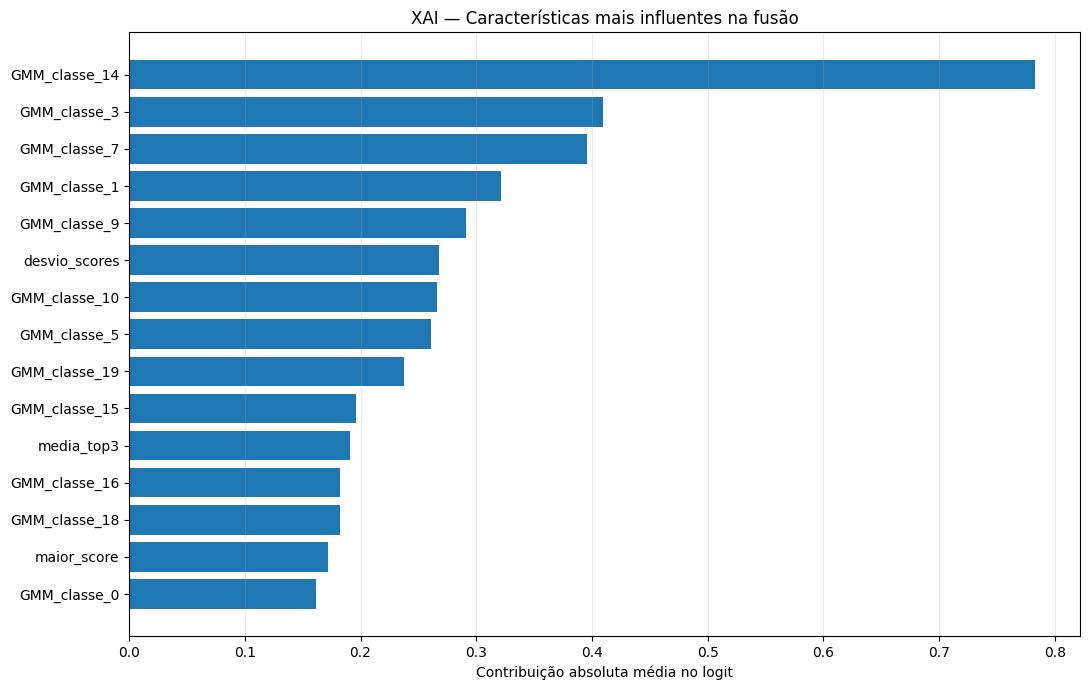


RANKING DOS 20 GMMs:


,caracteristica,coeficiente,importancia_absoluta,contribuicao_media_absoluta
14,GMM_classe_14,-1.0060,1.0060,0.7825
3,GMM_classe_3,0.5039,0.5039,0.4096
7,GMM_classe_7,0.4751,0.4751,0.3957
1,GMM_classe_1,0.4105,0.4105,0.3217
9,GMM_classe_9,0.3581,0.3581,0.2912
10,GMM_classe_10,0.3324,0.3324,0.2656
5,GMM_classe_5,-0.3416,0.3416,0.2606
19,GMM_classe_19,0.2868,0.2868,0.2376
15,GMM_classe_15,0.2523,0.2523,0.1959
16,GMM_classe_16,0.2173,0.2173,0.1822


In [11]:

# ============================================================
# XAI 1 — IMPORTÂNCIA GLOBAL NA REGRESSÃO LOGÍSTICA
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# 20 scores transformados + 6 características de fusão
nomes_fusao = (
    [f'GMM_classe_{i}' for i in range(20)] +
    [
        'maior_score',
        'segundo_maior_score',
        'media_top3',
        'logsumexp',
        'desvio_scores',
        'quantidade_scores_altos'
    ]
)

assert len(nomes_fusao) == 26

# Modelo final
modelo_xai = modelo_fusao_gmm_2p5s

scaler_xai = modelo_xai.named_steps['standardscaler']
regressao_xai = modelo_xai.named_steps['logisticregression']

coeficientes = regressao_xai.coef_[0]

# Contribuições calculadas nos dados de desenvolvimento
F_dev_padronizado = scaler_xai.transform(
    meta_dev_2p5s['F']
)

contribuicoes_dev = (
    F_dev_padronizado * coeficientes
)

importancia_global = pd.DataFrame({
    'caracteristica': nomes_fusao,
    'coeficiente': coeficientes,
    'importancia_absoluta': np.abs(coeficientes),
    'contribuicao_media_absoluta': np.abs(
        contribuicoes_dev
    ).mean(axis=0)
})

importancia_global = importancia_global.sort_values(
    'contribuicao_media_absoluta',
    ascending=False
)

print("IMPORTÂNCIA GLOBAL — REGRESSÃO LOGÍSTICA")
display(importancia_global.round(4))

# Gráfico das 15 mais influentes
top15 = importancia_global.head(15).iloc[::-1]

plt.figure(figsize=(11, 7))

plt.barh(
    top15['caracteristica'],
    top15['contribuicao_media_absoluta']
)

plt.xlabel('Contribuição absoluta média no logit')
plt.title('XAI — Características mais influentes na fusão')
plt.grid(axis='x', alpha=0.25)
plt.tight_layout()
plt.show()

# Avaliar especificamente os 20 especialistas
importancia_gmms = importancia_global[
    importancia_global['caracteristica'].str.startswith(
        'GMM_classe_'
    )
].copy()

print("\nRANKING DOS 20 GMMs:")
display(importancia_gmms.round(4))

EXPLICAÇÃO DA GRAVAÇÃO
Arquivo: 5-117118-A-42.wav
Categoria: siren
Classe real: 1
Classe prevista: 0

Probabilidade de anomalia:
Segmento 1: 0.4926
Segmento 2: 0.6641
Média final: 0.5784
Limiar: 0.6018

CARACTERÍSTICAS MAIS INFLUENTES:


,caracteristica,contrib_segmento_1,contrib_segmento_2,contrib_media,intensidade_media
24,desvio_scores,0.2293,0.3119,0.2706,0.2706
14,GMM_classe_14,-0.0996,-0.4350,-0.2673,0.2673
3,GMM_classe_3,0.0821,0.4405,0.2613,0.2613
1,GMM_classe_1,-0.3137,-0.1704,-0.2420,0.2420
20,maior_score,0.3065,0.0675,0.1870,0.1870
8,GMM_classe_8,0.0470,0.3133,0.1802,0.1802
19,GMM_classe_19,0.1921,0.1417,0.1669,0.1669
12,GMM_classe_12,0.1755,0.1490,0.1623,0.1623
15,GMM_classe_15,-0.1593,-0.1634,-0.1613,0.1613
9,GMM_classe_9,-0.0036,0.3189,0.1576,0.1613


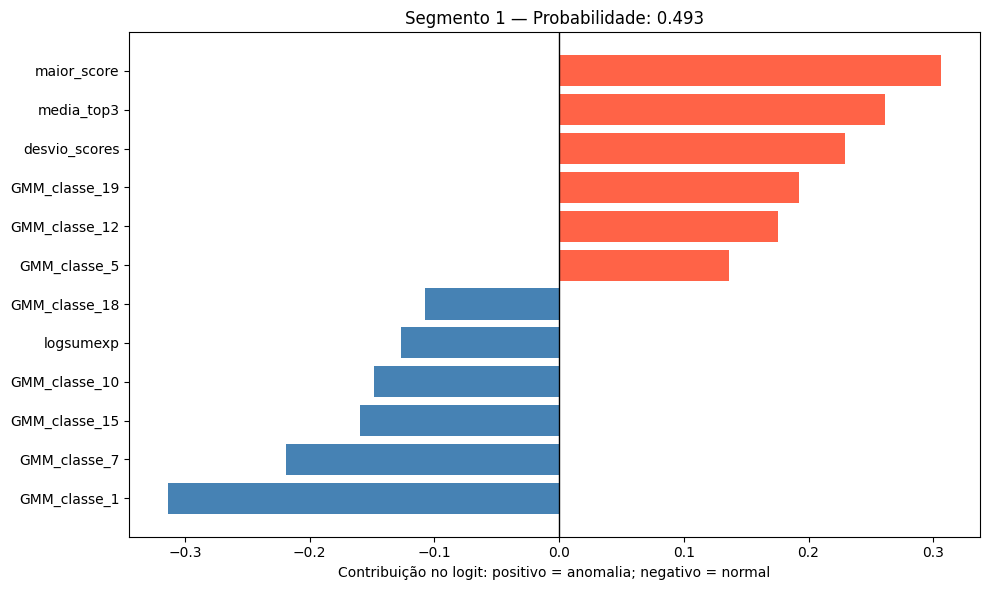

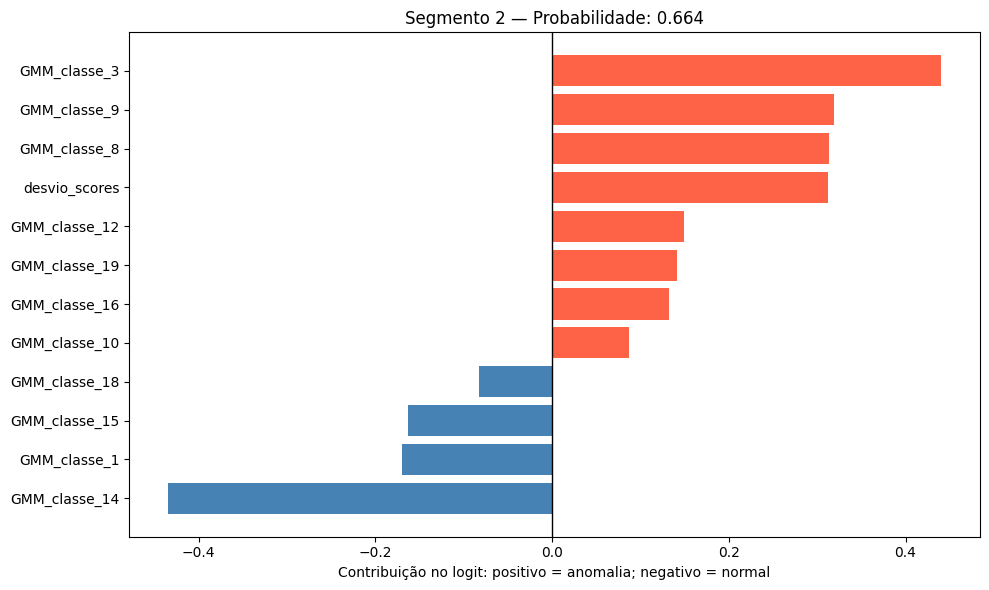

In [12]:

# ============================================================
# XAI 2 — EXPLICAÇÃO LOCAL DE UMA GRAVAÇÃO
# ============================================================

from scipy.special import expit

# Escolher automaticamente um falso negativo
falsos_negativos = predicoes_gmm_2p5s[
    (predicoes_gmm_2p5s['y_real'] == 1) &
    (predicoes_gmm_2p5s['pred_binaria'] == 0)
]

if len(falsos_negativos) > 0:
    arquivo_exemplo = falsos_negativos.iloc[0]['filename']
else:
    arquivo_exemplo = predicoes_gmm_2p5s.iloc[0]['filename']

# Para investigar outro áudio, altere manualmente:
# arquivo_exemplo = 'nome_do_audio.wav'

tabela_teste = meta_teste_2p5s['tabela']

indices = np.where(
    tabela_teste['filename'].to_numpy() == arquivo_exemplo
)[0]

# Ordenar os dois segmentos temporalmente
indices = indices[
    np.argsort(tabela_teste.iloc[indices]['segmento'])
]

assert len(indices) == 2, "Esperados dois segmentos por áudio"

# Recuperar as características da fusão
F_audio = meta_teste_2p5s['F'][indices]

# Padronização aplicada pela regressão logística
F_padronizado = scaler_xai.transform(F_audio)

# Contribuição individual no logit (antes da sigmoide)
contribuicoes = F_padronizado * coeficientes

intercepto = float(regressao_xai.intercept_[0])

logits = intercepto + contribuicoes.sum(axis=1)
probabilidades = expit(logits)

# Conferência com a previsão original
assert np.allclose(
    probabilidades,
    scores_segmentos_teste[indices]
)

probabilidade_final = probabilidades.mean()

predicao_final = int(
    probabilidade_final >= limiar_gmm_2p5s
)

# Informações do áudio
registro = predicoes_gmm_2p5s[
    predicoes_gmm_2p5s['filename'] == arquivo_exemplo
].iloc[0]

print("=" * 65)
print("EXPLICAÇÃO DA GRAVAÇÃO")
print("=" * 65)

print("Arquivo:", arquivo_exemplo)
print("Categoria:", registro['category'])
print("Classe real:", registro['y_real'])
print("Classe prevista:", predicao_final)

print("\nProbabilidade de anomalia:")
print("Segmento 1:", round(probabilidades[0], 4))
print("Segmento 2:", round(probabilidades[1], 4))
print("Média final:", round(probabilidade_final, 4))
print("Limiar:", round(limiar_gmm_2p5s, 4))

# Tabela de contribuições locais
explicacao_local = pd.DataFrame({
    'caracteristica': nomes_fusao,
    'contrib_segmento_1': contribuicoes[0],
    'contrib_segmento_2': contribuicoes[1],
    'contrib_media': contribuicoes.mean(axis=0),
    'intensidade_media': np.abs(contribuicoes).mean(axis=0)
})

explicacao_local = explicacao_local.sort_values(
    'intensidade_media',
    ascending=False
)

print("\nCARACTERÍSTICAS MAIS INFLUENTES:")
display(explicacao_local.head(15).round(4))

# Gráficos separados por segmento
for i in range(2):

    df_plot = pd.DataFrame({
        'caracteristica': nomes_fusao,
        'contribuicao': contribuicoes[i]
    })

    df_plot['abs'] = df_plot['contribuicao'].abs()

    df_plot = (
        df_plot.sort_values('abs', ascending=False)
        .head(12)
        .sort_values('contribuicao')
    )

    plt.figure(figsize=(10, 6))

    cores = [
        'tomato' if valor > 0 else 'steelblue'
        for valor in df_plot['contribuicao']
    ]

    plt.barh(
        df_plot['caracteristica'],
        df_plot['contribuicao'],
        color=cores
    )

    plt.axvline(0, color='black', linewidth=1)

    plt.title(
        f'Segmento {i + 1} — '
        f'Probabilidade: {probabilidades[i]:.3f}'
    )

    plt.xlabel(
        'Contribuição no logit: '
        'positivo = anomalia; negativo = normal'
    )

    plt.tight_layout()
    plt.show()

ROC-AUC original na validação: 0.7987

IMPORTÂNCIA DOS 12 ATRIBUTOS ACÚSTICOS:


,atributo,auc_original,auc_permutada_media,queda_auc_media,desvio_queda_auc,min_queda_auc,max_queda_auc
0,delta_delta_1_min,0.7987,0.7599,0.0388,0.0084,0.0265,0.0479
1,delta_delta_3_max,0.7987,0.7788,0.0199,0.0065,0.0098,0.0278
2,centroid_max,0.7987,0.7876,0.0111,0.0091,0.0012,0.0245
3,mfcc_3_std,0.7987,0.7921,0.0066,0.0117,-0.0118,0.0247
4,delta_4_std,0.7987,0.7925,0.0062,0.0130,-0.0095,0.0205
5,centroid_mean,0.7987,0.7926,0.0060,0.0127,-0.0104,0.0245
6,mfcc_1_max,0.7987,0.7942,0.0045,0.0154,-0.0130,0.0252
7,mfcc_1_mean,0.7987,0.7946,0.0040,0.0068,-0.0034,0.0143
8,mfcc_2_min,0.7987,0.7951,0.0036,0.0076,-0.0075,0.0141
9,mfcc_2_max,0.7987,0.7958,0.0029,0.0076,-0.0095,0.0106


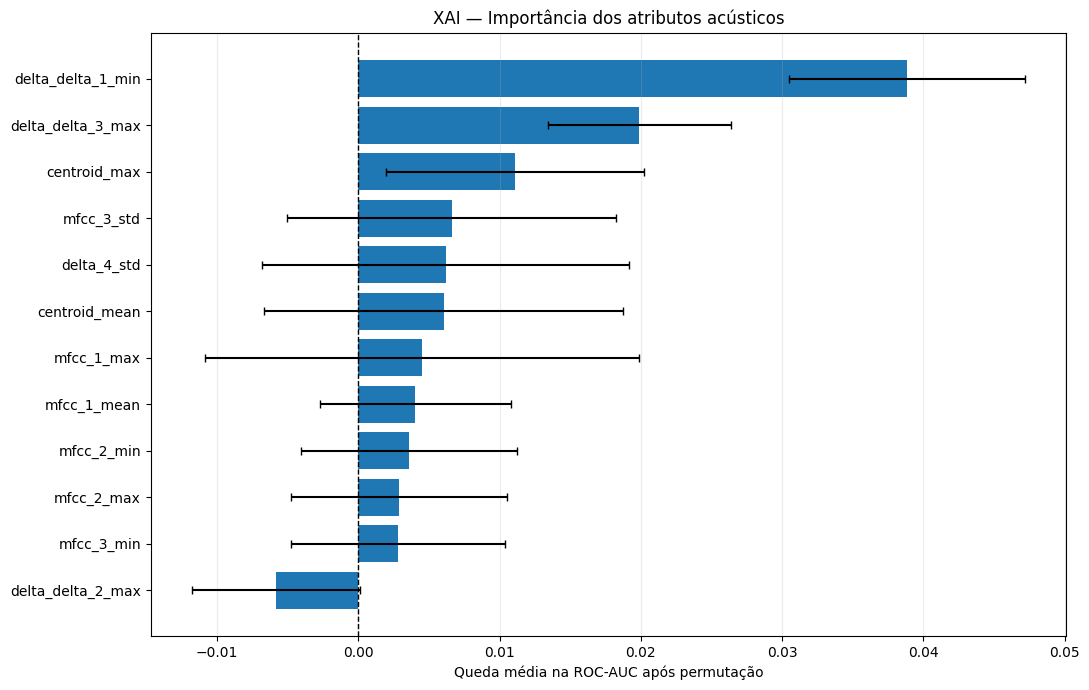

In [13]:

# ============================================================
# XAI 3 — IMPORTÂNCIA DOS 12 ATRIBUTOS ACÚSTICOS
# Permutação com validação cruzada no fold 4
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import StratifiedGroupKFold
from sklearn.metrics import roc_auc_score

N_REPETICOES = 5
rng_xai = np.random.default_rng(SEMENTE)

F = meta_dev_2p5s['F']
y = meta_dev_2p5s['y']
grupos = meta_dev_2p5s['grupos']
tabela_dev = meta_dev_2p5s['tabela']
cfg = meta_dev_2p5s['cfg']

cv_xai = StratifiedGroupKFold(
    n_splits=4,
    shuffle=True,
    random_state=SEMENTE
)

# ============================================================
# 1. RECUPERAR OS MODELOS DE CADA DOBRA
# ============================================================

dobras_xai = []
scores_baseline = np.full(len(y), np.nan)

for tr, ho in cv_xai.split(F, y, groups=grupos):

    modelo_cv = treinar_modelo_fusao(
        F[tr], y[tr]
    )

    scores_baseline[ho] = pontuar_modelo_fusao(
        modelo_cv, F[ho]
    )

    dobras_xai.append((ho, modelo_cv))

assert np.isfinite(scores_baseline).all()

# Agregar as previsões por gravação original
baseline_audio = agregar_por_audio(
    tabela_dev, scores_baseline
)

auc_baseline = roc_auc_score(
    baseline_audio['y_real'],
    baseline_audio['score']
)

print("ROC-AUC original na validação:",
      round(auc_baseline, 4))


# ============================================================
# 2. FUNÇÃO: EMBARALHAR UM ATRIBUTO ENTRE GRAVAÇÕES
# Mantém os dois segmentos do mesmo arquivo juntos
# ============================================================

def permutar_atributo_por_audio(tabela, atributo, rng):

    dados = tabela.copy()

    arquivos = dados['filename'].drop_duplicates().to_numpy()

    # Cada áudio possui dois segmentos
    matriz = dados.pivot(
        index='filename',
        columns='segmento',
        values=atributo
    ).reindex(index=arquivos, columns=[1, 2])

    assert matriz.notna().all().all()

    valores = matriz.to_numpy()

    # Permutar gravações, preservando o par de segmentos
    valores_permutados = valores[
        rng.permutation(len(arquivos))
    ]

    mapa = pd.Series(
        np.arange(len(arquivos)),
        index=arquivos
    )

    indice_audio = dados['filename'].map(
        mapa
    ).to_numpy(dtype=int)

    indice_segmento = (
        dados['segmento'].to_numpy(dtype=int) - 1
    )

    dados[atributo] = valores_permutados[
        indice_audio, indice_segmento
    ]

    return dados


# ============================================================
# 3. PERMUTAR CADA ATRIBUTO E MEDIR QUEDA NA ROC-AUC
# ============================================================

resultados_xai = []

for atributo in atributos_finais:

    aucs_permutadas = []

    for repeticao in range(N_REPETICOES):

        scores_permutados = np.full(len(y), np.nan)

        for ho, modelo_cv in dobras_xai:

            # Apenas gravações da dobra de validação
            tabela_hold = tabela_dev.iloc[ho].copy()

            # Alterar um atributo acústico
            tabela_modificada = permutar_atributo_por_audio(
                tabela_hold,
                atributo,
                rng_xai
            )

            # Recalcular os scores dos mesmos 20 GMMs
            S = scores_20_gmms(
                tabela_modificada,
                experimento_gmm_2p5s
            )

            # Recriar as 26 características de fusão
            F_modificado = caracteristicas_fusao(
                S, cfg
            )

            # Usar o mesmo modelo de regressão da dobra
            scores_permutados[ho] = pontuar_modelo_fusao(
                modelo_cv,
                F_modificado
            )

        assert np.isfinite(scores_permutados).all()

        dados_audio = agregar_por_audio(
            tabela_dev,
            scores_permutados
        )

        auc = roc_auc_score(
            dados_audio['y_real'],
            dados_audio['score']
        )

        aucs_permutadas.append(auc)

    quedas = auc_baseline - np.array(aucs_permutadas)

    resultados_xai.append({
        'atributo': atributo,
        'auc_original': auc_baseline,
        'auc_permutada_media': np.mean(aucs_permutadas),
        'queda_auc_media': np.mean(quedas),
        'desvio_queda_auc': np.std(quedas),
        'min_queda_auc': np.min(quedas),
        'max_queda_auc': np.max(quedas)
    })


# ============================================================
# 4. RANKING FINAL DOS ATRIBUTOS
# ============================================================

importancia_acustica = pd.DataFrame(
    resultados_xai
).sort_values(
    'queda_auc_media',
    ascending=False
).reset_index(drop=True)

print("\nIMPORTÂNCIA DOS 12 ATRIBUTOS ACÚSTICOS:")
display(importancia_acustica.round(4))


# ============================================================
# 5. GRÁFICO DE IMPORTÂNCIA
# ============================================================

plot = importancia_acustica.iloc[::-1]

plt.figure(figsize=(11, 7))

plt.barh(
    plot['atributo'],
    plot['queda_auc_media'],
    xerr=plot['desvio_queda_auc'],
    capsize=3
)

plt.axvline(
    0, color='black', linestyle='--', linewidth=1
)

plt.xlabel('Queda média na ROC-AUC após permutação')
plt.title('XAI — Importância dos atributos acústicos')
plt.grid(axis='x', alpha=0.25)
plt.tight_layout()
plt.show()


### Observações metodológicas para o TCC

- Os **GMMs** estimam distribuições a partir de sons normais; a **regressão logística** usa rótulos de normal/anomalia no fold 4. Portanto, o sistema completo é **híbrido (modelagem normal + fusão supervisionada)**.
- As duas metades de uma mesma gravação não são observações independentes; os grupos de validação respeitam `src_file` (ou `filename` quando ausente).
- A normalização dos scores utiliza referências fora-da-amostra produzidas durante o treinamento dos GMMs.
- O critério de classificação por áudio é a **média** das probabilidades dos dois segmentos, com limiar selecionado no fold 4.
- Os resultados do fold 5 não devem orientar novas escolhas de hiperparâmetros; avaliar versões futuras com separação independente adequada.